# Taxi-out time: from the inputs to the submission file

One run, top to bottom: check the inputs, build (or read) the feature table, train the stages with month-block
cross-validation, predict one held-out month of 2025 as a check, refit on all of 2025, predict the ranking set and write
the submission file. The code is in `src/taxiout/` (the pipeline) and `src/v77/stages.py` (one function per step);
settings and inputs are in `src/v77/v77.yaml` and `configs/paths.json`. Every output goes to `results/v77/<run>/`.

Switches, read from the environment:

| switch | values | meaning |
|---|---|---|
| `V77_SMOKE` | `1` (default) / `0` | 5% of the days with small models, a quick check that every step runs / **the full run** (~12.5 h on a GPU) |
| `V77_FEATURES` | `pinned` (default) / `build` | read the pinned feature table / **build it from the raw inputs** |
| `V77_DEVICE` | unset / `CPU` / `GPU` | the device in the YAML (GPU) / CatBoost on the CPU (no GPU needed, slower) |
| `V77_FETCH` | `0` (default) / `1` | stop if a needed input is missing / **download the missing METAR and Open-Meteo inputs first** |
| `V77_HEDGE` | `0` (default) / `1` | Rome stage as configured / the optional Rome hedge settings (`hedge_options` in the YAML) |

In [1]:
import os, json, time
import numpy as np, pandas as pd
from pathlib import Path
import sys; sys.path.insert(0, str(Path.cwd() / "src"))  # run from the repository root
from v77 import stages as S
from taxiout.pipeline import STAGES

SMOKE = os.environ.get("V77_SMOKE", "1") == "1"            # V77_SMOKE=0 trains everything
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
cfg = S.load_config(); FEATURES = S.features_mode(cfg)
print("mode:", "SMOKE" if SMOKE else "FULL", "| features:", FEATURES)

mode: SMOKE | features: pinned


## 1. Inputs

Every input from `configs/paths.json`: whether this mode needs it (`pinned`: the organiser files and the pinned feature
table; `build`: every raw input), whether it was found, and how to get it. The run stops here if something is missing.

In [2]:
chk = S.input_check(cfg)
if os.environ.get("V77_FETCH", "0") == "1" and (chk.needed & ~chk.found).any():
    chk = S.fetch_missing(cfg, chk)
display(chk[["input", "needed", "found", "entries", "path", "fetch"]])
missing = chk[chk.needed & ~chk.found]
for _, r in missing.iterrows():
    print(f"MISSING {r['input']} ({r['path']}): {r['how to get it']}")
assert missing.empty, f"inputs needed in '{FEATURES}' mode are missing: {missing.input.tolist()} (see above; V77_FETCH=1 downloads METAR / Open-Meteo)"
raw = S.raw_inventory(cfg, hash_organiser=not SMOKE)
display(raw["organiser_files"])

,input,needed,found,entries,path,fetch
0,organiser,True,True,30,\2026\data\raw\official,
1,features_file,True,True,1,data\features\feat...,
2,adsb_clocks,False,True,1712,\prc2026-taxiout\data\stand_clock,
3,metar,False,True,1441,\prc2026_nm_reconstruction\data...,yes
4,open_meteo,False,True,1,\prc2026_nm_reconstruction\data...,yes
5,eurocontrol,False,True,40,\prc2026_nm_reconstruction\data...,
6,atfm,False,True,1,\prc2026_nm_reconstruction\data...,
7,opdi,False,True,4,\2026\data\external\opdi,
8,extra,False,True,494,data\extra,


,file,bytes,sha256
0,training_2025-01-01_2025-02-01.parquet,21218481,
1,training_2025-02-01_2025-03-01.parquet,19824510,
2,training_2025-03-01_2025-04-01.parquet,22606072,
3,training_2025-04-01_2025-05-01.parquet,23840340,
4,training_2025-05-01_2025-06-01.parquet,25187756,
5,training_2025-06-01_2025-07-01.parquet,24991697,
6,training_2025-07-01_2025-08-01.parquet,26014977,
7,training_2025-08-01_2025-09-01.parquet,25969246,
8,training_2025-09-01_2025-10-01.parquet,25102673,
9,training_2025-10-01_2025-11-01.parquet,25392098,


## 2. Settings

The model settings from the YAML, compared field by field with the settings of the reference run (in smoke mode only
the smoke settings differ).

In [3]:
s = S.make_settings(cfg, smoke=SMOKE)
OUT = S.run_dir(cfg, SMOKE); print("run folder:", OUT)
print("non-default settings:", json.dumps(S.non_default_settings(s), default=str))
diff = S.settings_vs_reference(s, cfg)
print("fields differing from the reference run:" if len(diff) else "every setting equals the reference run's")
diff

run folder: results\v77\20261013T225529_smoke
non-default settings: {"holdout_months": [7], "trees": 150, "expert_trees": 100, "lgb_trees": 100, "spec_trees": 100, "spec_seeds": 1, "nb_skip_airports": "LIRF", "drop": ["context", "inbound", "eu_monthly", "seasonal", "om_drift"], "family_airports": {"hotspots": ["EDDF", "EHAM", "LEBL"], "hotspots2": ["EDDF", "EHAM", "LEBL"]}, "gate_trees": 100, "lirf_regime_seeds": 1, "regime_seeds": 1, "verbose": 0, "sample_days": 0.05}
fields differing from the reference run:


,field,this,reference
0,trees,150.00,4100.0
1,expert_trees,100.00,2000.0
2,lgb_trees,100.00,1650.0
3,spec_trees,100.00,1500.0
4,spec_seeds,1.00,5.0
5,main_seeds,1.00,4.0
6,gate_trees,100.00,1500.0
7,lirf_regime_seeds,1.00,3.0
8,regime_seeds,1.00,3.0
9,sample_days,0.05,1.0


## 3. Features

`pinned`: the fixed feature table (size and SHA-256 checked). `build`: the table is built from the raw inputs
(movements, field filling, ADS-B clocks, weather, EUROCONTROL statistics, ADS-B derived inputs) and cached. Then the
2025 training rows and the 2026 ranking rows are split.

In [4]:
if FEATURES == "pinned":
    info = S.verify_feature_file(cfg); print(json.dumps(info, indent=1))
    assert info["exists"] and info["bytes_ok"] and info.get("sha256_ok", True), "the feature file is not the pinned one"
else:
    info = {"mode": "build"}; print("building the feature table from the raw inputs (cached afterwards under data/features/)")
ft = S.feature_table(cfg, s); f, tr, rk, cat_levels, meta = ft["f"], ft["tr"], ft["rk"], ft["cat_levels"], ft["meta"]
info["features_file"] = ft["hashes"].get("features_file", "built"); info["columns"] = f.shape[1]
print(f"features: {f.shape[0]:,} departures x {f.shape[1]} columns; train rows used {len(tr):,} (sample_days {s.sample_days}); ranking rows {len(rk):,}")

{
 "file": "data\\features\\features_f391f7893a3cde99.parquet",
 "exists": true,
 "bytes": 615319694,
 "bytes_ok": true,
 "sha256": "fcb6de88b34bbbdc33a17178c60fc899844d70faa6986dc42004f04160462e4a",
 "sha256_ok": true
}
[22:55:29] features from the fixed file data\features\features_f391f7893a3cde99.parquet (PRC_FEATURES)


features: 2,429,888 departures x 338 columns; train rows used 105,149 (sample_days 0.05); ranking rows 344,841


## 4. What the model reads

Every feature column by family, whether the main model uses it, and its missing share for departures with and without
an NM flight plan.

In [5]:
inv = S.feature_inventory(f, s); inv.to_csv(OUT / "feature_inventory.csv", index=False)
print(f"{len(inv)} columns; model A inputs: {int(inv.model_A_input.sum())}")
summary = inv.groupby(["family", "role"]).agg(columns=("column", "size"), missing_nm=("missing_nm", "mean"), missing_no_nm=("missing_no_nm", "mean")).round(3)
summary

338 columns; model A inputs: 296


columns  missing_nm  missing_no_nm
family        role                                                                  
adsb_where    model A input                             8       0.391          0.634
agreement     model A input                             6       0.001          0.833
airport_state model A input                            45       0.018          0.027
arrival_ctx   model A input                            16       0.302          0.292
context       dropped family                           10       0.028          0.125
core          key / split / label / time                5       0.000          0.000
              model A input                            79       0.094          0.253
              raw organiser field (stage 2 only)        4       0.000          0.000
eu_monthly    dropped family                            9       0.000          0.000
horizon       model A input                             6       0.000          0.000
hotspots      restricted to airports                    9       0.699          0.770
hotspots2     restricted to airports                   13       0.701          0.795
inbound       dropped family                            6       0.280          0.494
om_drift      dropped family                            4       0.021          0.013
om_showers    model A input                             1       0.086          0.051
opdi          model A input                             3       0.477          0.593
pairs         model A input                             1       0.000          0.000
postops       model A input                             2       0.153          0.117
queue_comp    model A input                             4       0.011          0.038
queue_detail  model A input                            16       0.006          0.088
seasonal      dropped family                            4       0.000          0.000
spreads       model A input                             6       0.000          1.000
stamp         model A input                             6       0.166          0.166
taxi_dyn      model A input                            15       0.469          0.774
wake          model A input                             6       0.003          0.013
weather       model A input                            54       0.006          0.004

In [6]:
inv[inv.role == "model A input"].groupby("family").size().sort_values(ascending=False).to_frame("model A columns")

,model A columns
family,
core,79
weather,54
airport_state,45
queue_detail,16
arrival_ctx,16
taxi_dyn,15
adsb_where,8
horizon,6
agreement,6


## 5. Data overview

Departures per airport, the share without an NM flight plan, label quantiles, and Rome's departures without an NM
flight plan by their gap to the schedule.

In [7]:
eda = S.eda_tables(tr, rk)
display(eda["rows_by_airport_set"]); display(eda["no_nm_share_by_airport"])
print("plausible-label view drops", eda["plausible_view_dropped_rows"], "training rows (label more than 12 h over the schedule gap)")
display(eda["label_quantiles_s"])
display(eda["lirf_no_nm_by_gap_band"])
for p in S.eda_plots(tr, OUT): print("plot:", p)

_set,rank 2026,train 2025
airport,,
EDDF,36317,11722
EDDM,25966,8413
EGLL,39840,11979
EHAM,38182,12343
LEBL,30080,9146
LEMD,36954,10651
LFPG,39872,12076
LIRF,26899,8164
LSZH,23150,6785


_set,rank 2026,train 2025
airport,,
EDDF,0.0116,0.0084
EDDM,0.0092,0.0065
EGLL,0.0062,0.0037
EHAM,0.0316,0.0147
LEBL,0.0147,0.0116
LEMD,0.0064,0.0040
LFPG,0.0184,0.0235
LIRF,0.0142,0.0094
LSZH,0.0285,0.0140


plausible-label view drops 1 training rows (label more than 12 h over the schedule gap)


0.10    0.50     0.90     0.99
pop   airport                                 
NM    EDDF     477.0   837.0   1248.0   1871.0
      EDDM     538.0   780.0   1139.0   1885.0
      EGLL     910.0  1321.0   1808.0   2516.0
      EHAM     462.0   727.0   1113.0   1730.0
      LEBL     597.0   912.0   1365.0   1880.0
      LEMD     644.0   985.0   1370.0   1880.0
      LFPG     656.0   956.0   1443.0   2395.0
      LIRF     669.0  1021.0   1627.0   3297.0
      LSZH     402.0   712.0   1064.0   1621.0
      LTFM     660.0   963.0   1498.0   2333.0
no-NM EDDF     542.0   892.0   1303.0   2663.0
      EDDM     614.0   901.0   1280.0   2469.0
      EGLL     892.0  1372.0   1684.0   2540.0
      EHAM     118.0   523.0   1079.0   2456.0
      LEBL     668.0  1066.0   1476.0   1856.0
      LEMD     614.0  1061.0   1589.0   2781.0
      LFPG     656.0  1026.0   1542.0   2642.0
      LIRF     848.0  5458.0  12628.0  30992.0
      LSZH      -4.0   690.0    971.0   1339.0
      LTFM     660.0   930.0   1383.0   1957.0

class,day-shift,ordinary / other,stamped
gap band,,,
"[0.5, 1.0)",0,2,1
"[1.0, 2.0)",0,15,20
"[14.0, 20.0)",0,0,1
"[2.0, 4.0)",1,9,18
"[4.0, 8.0)",0,1,5


plot: results\v77\20261013T225529_smoke\eda_labels.png
plot: results\v77\20261013T225529_smoke\eda_lirf_label_vs_gap.png


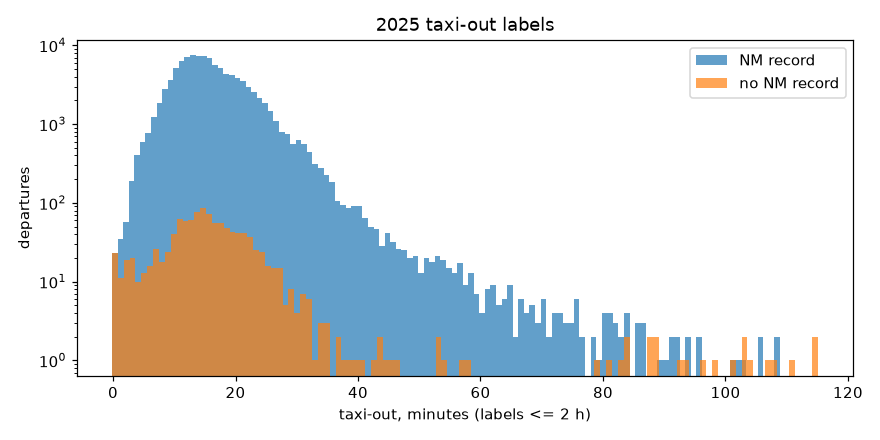

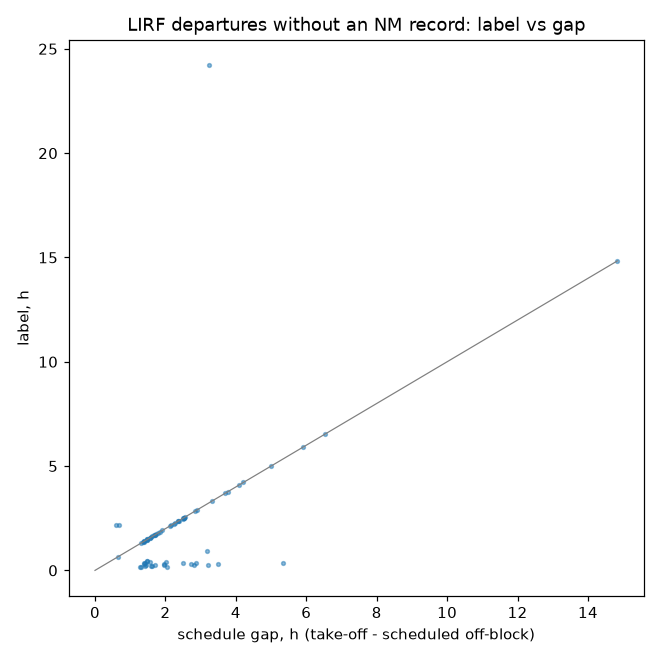

In [8]:
from IPython.display import Image, display as _d
for p in sorted(OUT.glob("eda_*.png")): _d(Image(filename=str(p), width=700))

## 6. Training, out of fold: regime, anchor, main model, neighbours, LightGBM, experts

One month of 2025 is held out. The other eleven months are cross-validated in contiguous month blocks: the regime
classifier, the anchor, the main CatBoost model on the anchor residual, the runway-neighbour refit, LightGBM and the
blend, and the airport experts. Every number is out of fold.

In [9]:
month_results = {}
for tm in s.holdout_months:
    sp = S.dev_split(tr, s, tm); dev, test, folds = sp["dev"], sp["test"], sp["folds"]
    print(f"test month {tm}: development rows {len(dev):,} in month blocks {folds}; test rows {len(test):,}")
    cv = S.cv_stages_2_to_6(dev, folds, s, cat_levels)
    display(S.stage_table(dev, cv["oof"], ["anchor", "model_A", "model_A_neighbours", "lightgbm", "blend", "experts"]))
    print("blend weight model A:", round(cv["base_choices"]["blend_weight_model_A"], 4), "| expert shares:", cv["base_choices"]["expert_weights"])
    month_results[tm] = {"split": sp, "cv": cv}

test month 7: development rows 98,944 in month blocks [(2, 4), (6, 8), (9, 11), (12,)]; test rows 6,205
[22:55:58]   fold (2, 4): stage 2 regime, stage 3 anchor


[22:56:47]   fold (2, 4): stage 4 model A on 82,177 rows


[22:56:51]   fold (2, 4): anchor 229.75 -> model A 200.56


[22:56:51]   fold (6, 8): stage 2 regime, stage 3 anchor


[22:57:35]   fold (6, 8): stage 4 model A on 61,895 rows


...

[23:00:46]   fold (12,): + neighbours 196.65; LightGBM 193.32


[23:01:04]   fold (12,): stage 6b airport experts on 16,506 rows


[23:01:04]   stage 6b expert share by airport: {'EDDF': 1.0, 'EDDM': 1.0, 'EGLL': 0.75, 'EHAM': 0.5, 'LEBL': 0.5, 'LEMD': 0.5, 'LFPG': 0.5, 'LIRF': 0.75, 'LSZH': 1.0, 'LTFM': 0.75}


,all,labels_le_2h,nm_outside_lirf,nm_lirf,no_nm,no_nm_lirf,top10_sse_share,rows
stage,,,,,,,,
anchor,385.23,263.75,228.25,407.18,2903.49,10944.31,0.56,98944
model_A,365.48,241.70,198.60,387.45,2869.29,10851.45,0.61,98944
model_A_neighbours,365.43,242.21,195.20,393.98,2882.41,10899.64,0.61,98944
lightgbm,366.71,238.70,195.76,391.70,2896.89,10958.03,0.62,98944
blend,364.48,239.19,194.20,390.57,2880.18,10894.16,0.62,98944
experts,362.51,236.45,191.34,387.76,2875.93,10880.33,0.63,98944


blend weight model A: 0.6121 | expert shares: {'EDDF': 1.0, 'EDDM': 1.0, 'EGLL': 0.75, 'EHAM': 0.5, 'LEBL': 0.5, 'LEMD': 0.5, 'LFPG': 0.5, 'LIRF': 0.75, 'LSZH': 1.0, 'LTFM': 0.75}


## 7. Training, out of fold: specialists and ADS-B gates

Specialists for departures without an NM flight plan (kept per airport where they win out of fold) and the ADS-B
gates. These choices are then fixed.

In [10]:
for tm, r in month_results.items():
    top = S.cv_stages_7_to_8(r["split"]["dev"], r["split"]["folds"], r["cv"], s)
    r["oof"], r["choices"] = top["oof"], top["choices"]
    display(S.stage_table(r["split"]["dev"], r["oof"]))
    ch = r["choices"]; print("specialists:", ch["specialist_airports"], "| gates:", {k: v["airports"] for k, v in ch["gates"].items()})

[23:01:05]   fold (2, 4): stage 7 specialist 'all_resid' on 940 rows


[23:01:06]   fold (6, 8): stage 7 specialist 'all_resid' on 514 rows


[23:01:07]   fold (9, 11): stage 7 specialist 'all_resid' on 770 rows


[23:01:08]   fold (12,): stage 7 specialist 'all_resid' on 878 rows


[23:01:09]   gate nm fold (2, 4): fit on 52,750 rows


...

[23:01:59]   gate no_nm fold (9, 11): fit on 298 rows


[23:02:22]   gate no_nm fold (12,): fit on 293 rows


[23:02:45]   choices (made on these rows only): blend weight 0.612; specialist at {}; gate nm at ['EDDF', 'EDDM', 'EGLL', 'EHAM', 'LEBL', 'LEMD', 'LIRF', 'LSZH', 'LTFM']; gate no_nm at ['EDDF', 'EDDM', 'EGLL', 'EHAM', 'LEBL', 'LEMD', 'LIRF', 'LSZH', 'LTFM']


,all,labels_le_2h,nm_outside_lirf,nm_lirf,no_nm,no_nm_lirf,top10_sse_share,rows
stage,,,,,,,,
anchor,385.23,263.75,228.25,407.18,2903.49,10944.31,0.56,98944
model_A,365.48,241.70,198.60,387.45,2869.29,10851.45,0.61,98944
model_A_neighbours,365.43,242.21,195.20,393.98,2882.41,10899.64,0.61,98944
lightgbm,366.71,238.70,195.76,391.70,2896.89,10958.03,0.62,98944
blend,364.48,239.19,194.20,390.57,2880.18,10894.16,0.62,98944
experts,362.51,236.45,191.34,387.76,2875.93,10880.33,0.63,98944
specialist,362.51,236.45,191.34,387.76,2875.93,10880.33,0.63,98944
final,361.22,234.32,189.67,386.49,2871.32,10864.33,0.63,98944


specialists: {} | gates: {'nm': ['EDDF', 'EDDM', 'EGLL', 'EHAM', 'LEBL', 'LEMD', 'LIRF', 'LSZH', 'LTFM'], 'no_nm': ['EDDF', 'EDDM', 'EGLL', 'EHAM', 'LEBL', 'LEMD', 'LIRF', 'LSZH', 'LTFM']}


## 8. Held-out month

The stack trained on the other eleven months predicts the held-out month once: the honest check of the model, stage by
stage, next to the reference run's numbers.

In [11]:
for tm, r in month_results.items():
    res = S.fit_and_predict_month(r["split"]["dev"], r["split"]["test"], r["oof"], r["choices"], s, cat_levels, meta, OUT, tm)
    r.update(res)
    print(f"held-out month {tm}:"); display(S.stage_table(r["split"]["test"], r["pred"]))
hd = S.assemble_holdout(tr, s, month_results)
rep = S.holdout_report(hd, s, meta, OUT, cfg)
print("regime check:", json.dumps(rep["regime_check"], default=float))
cmp_hold = S.compare_holdout(rep, cfg); display(cmp_hold)
if SMOKE: print("smoke run: small models on 5% of the days, the numbers only check that every step runs")

[23:02:45] fit on 98,944 rows: regime, anchor


[23:03:36]   model A


[23:03:39]   model A + neighbours


[23:03:43]   LightGBM


[23:03:48]   airport expert EDDF on 11,023 rows


...

held-out month 7:


,all,labels_le_2h,nm_outside_lirf,nm_lirf,no_nm,no_nm_lirf,top10_sse_share,rows
stage,,,,,,,,
anchor,319.94,307.66,278.69,426.60,966.63,3902.82,0.22,6205
model_A,283.78,272.08,240.72,379.28,937.49,3940.45,0.26,6205
model_A_neighbours,281.15,268.59,235.97,385.67,942.55,3989.33,0.28,6205
lightgbm,276.51,265.20,233.14,379.21,914.74,3817.76,0.27,6205
blend,277.97,265.82,233.81,380.92,926.65,3908.84,0.28,6205
experts,269.61,258.65,227.55,358.91,906.43,3839.14,0.28,6205
specialist,269.61,258.65,227.55,358.91,906.43,3839.14,0.28,6205
final,271.74,248.43,226.39,351.32,962.51,4097.74,0.30,6205


regime check: {"auc_all_candidates": 0.9804345180136319, "auc_lirf_no_nm": 0.4444444444444444, "lirf_no_nm_mean_p": 0.5719122831934255, "lirf_no_nm_stamped_rate": 0.5}


,this run,reference run,difference,within_tolerance
anchor,319.94,419.41,-99.48,False
model_A,283.78,353.35,-69.57,False
model_A_neighbours,281.15,349.51,-68.36,False
lightgbm,276.51,356.51,-80.00,False
blend,277.97,349.27,-71.30,False
experts,269.61,348.04,-78.43,False
specialist,269.61,262.03,7.57,False
final,271.74,259.91,11.83,False


smoke run: small models on 5% of the days, the numbers only check that every step runs


## 9. Final fit and predictions

The stack is refitted on all of 2025 with the fixed choices and predicts the ranking set; the file is written in the
template's order.

In [12]:
subm = S.submission_pass(tr, rk, hd, s, cat_levels, meta, OUT)
print("ranking stage means (s):", {k: round(v, 1) for k, v in subm["report"]["ranking_stage_means"].items()})
print("choices:", json.dumps({k: subm["choices"][k] for k in ("blend_weight_model_A", "specialist_airports", "expert_weights")}, default=float))

[23:05:29] SUBMISSION: refit on all 105,149 departures; choices {"w": 0.612, "spec": {}, "experts": {"LTFM": 0.75, "EDDF": 1.0, "EDDM": 1.0, "LIRF": 0.75, "EGLL": 0.75, "LSZH": 1.0, "LEMD": 0.5, "LEBL": 0.5, "LFPG": 0.5, "EHAM": 0.5}, "gates": {"nm": ["EDDF", "EDDM", "EGLL", "EHAM", "LEBL", "LEMD", "LIRF", "LSZH", "LTFM"], "no_nm": ["EDDF", "EDDM", "EGLL", "EHAM", "LEBL", "LEMD", "LIRF", "LSZH", "LTFM"]}}


[23:05:29] fit on 105,149 rows: regime, anchor


[23:06:17]   model A


[23:06:21]   model A + neighbours


[23:06:24]   LightGBM


...

[23:06:47]   gate nm


[23:06:48]   gate no_nm


[23:08:11]   LIRF regime stage: weight chosen out-of-fold 1.0 (SSE at 0.5: 7.466e+09, at 1.0: 6.874e+09; 69 rows)


[23:08:11]   LIRF regime stage: classifier on 69 rows below 8 h (62% stamped; calibrated on 69 out-of-fold probabilities); ordinary taxi 1071 s


ranking stage means (s): {'anchor': 1024.0, 'model_A': 1031.6, 'model_A_neighbours': 1034.1, 'lightgbm': 1030.3, 'blend': 1032.3, 'experts': 1029.2, 'specialist': 1029.2, 'final': 1031.2}
choices: {"blend_weight_model_A": 0.6121135175491697, "specialist_airports": {}, "expert_weights": {"LTFM": 0.75, "EDDF": 1.0, "EDDM": 1.0, "LIRF": 0.75, "EGLL": 0.75, "LSZH": 1.0, "LEMD": 0.5, "LEBL": 0.5, "LFPG": 0.5, "EHAM": 0.5}}


## 10. LOBT window and the output file

On 2025, every departure with a LOBT has its off-block within a fixed window of it; predictions outside that window
are moved to its nearest edge.

In [13]:
prop = S.lobt_property_2025(cfg); print(json.dumps(prop, indent=1))
assert prop["exceptions_over_half_width"] == 0, "the LOBT property does not hold on 2025 - do not apply the window"
final, win = S.lobt_window(subm["sub"], cfg, subm["template_dtype"]); print(json.dumps(win, indent=1))
final.to_parquet(OUT / "submission_lobt_window.parquet", index=False)
print("final file:", OUT / "submission_lobt_window.parquet", "| rows", len(final), "| dtype", final.iloc[:, 1].dtype)

{
 "departures_2025_with_lobt": 2062577,
 "max_abs_block_minus_lobt_s": 3606.0,
 "exceptions_over_half_width": 0,
 "half_width_s": 3606
}


{
 "ranking_rows_with_lobt": 339551,
 "rows_moved": 143,
 "mean_abs_move_s": 660.7132867132867
}
final file: results\v77\20261013T225529_smoke\submission_lobt_window.parquet | rows 344841 | dtype int32


## 11. Published daily totals

EUROCONTROL publishes, per airport and day, the total pre-departure delay of the day's departures; on 2025 it equals the
sum over the day of max(0, take-off - schedule - taxi-out). Each day's predictions are reconciled with that total
(an equal shift of the day's delayed departures), every departure of the day then responds to the day's shift with a
loading fitted on this run's out-of-fold predictions, and a Rome / Istanbul departure without a flight plan whose
flight has a plan at the destination is kept outside the window around that plan's off-block. Skipped when the daily
table is not among the inputs.

In [14]:
from v77 import postprocess as PP
ppfit = PP.fit(pd.read_parquet(OUT / "dev_oof.parquet", columns=["MVT_ID_mvt", "final"]), cfg)
print("fit:", json.dumps({k: v for k, v in ppfit.items() if k != "loadings"}, indent=1))
final, pprep = PP.apply(final, ppfit, cfg); print("apply:", json.dumps(pprep, indent=1))
final.to_parquet(OUT / "submission_postprocessed.parquet", index=False); print("final file:", OUT / "submission_postprocessed.parquet")

fit: {
 "status": "fitted",
 "rows": 98944,
 "oof_rmse": {
  "before": 361.2208311242201,
  "reconciled": 359.825380162515,
  "loaded": 359.44845762189334,
  "orphan": 353.8411276432222
 },
 "share_on_reconciled_days": 0.043251782813528906,
 "orphans_recovered": 190,
 "orphans_moved": 5,
 "labels_inside_orphan_window": null
}


apply: {
 "status": "applied",
 "rows": 344841,
 "share_on_reconciled_days": 0.9429099208040808,
 "loadings_used": true,
 "orphans_recovered": 50,
 "orphans_moved": 31,
 "rows_moved": 316389,
 "mean_abs_move_s": 27.740004813812742,
 "mean_before": 1031.458460565884,
 "mean_after": 1029.528292749412
}
final file: results\v77\20261013T225529_smoke\submission_postprocessed.parquet


## 12. Results

The main numbers of this run into `results.yaml` in the run folder.

In [15]:
results = {"mode": "smoke" if SMOKE else "full", "features_mode": FEATURES, "run_folder": str(OUT), "settings_non_default": S.non_default_settings(s),
           "feature_file": info, "holdout_stage_rmse": {k: rep["holdout"][k]["all"] for k in STAGES},
           "holdout_final": {k: rep["holdout"]["final"][k] for k in ("all", "plausible", "labels_le_2h", "nm_outside_lirf", "nm_lirf", "no_nm", "no_nm_lirf", "top10_sse_share", "rows")},
           "regime_check": rep["regime_check"], "vs_reference_holdout": cmp_hold, "submission_choices": subm["choices"],
           "ranking_stage_means": subm["report"]["ranking_stage_means"], "lobt_property_2025": prop, "lobt_window": win,
           "postprocess_fit": {k: v for k, v in ppfit.items() if k != "loadings"}, "postprocess": pprep}
p = S.write_results(OUT, results); print("wrote", p)
import yaml; back = yaml.safe_load(p.read_text(encoding="utf-8")); print(yaml.safe_dump({k: back[k] for k in ("mode", "holdout_stage_rmse", "lobt_window")}, sort_keys=False))

wrote results\v77\20261013T225529_smoke\results.yaml
mode: smoke
holdout_stage_rmse:
  anchor: 319.9369470930039
  model_A: 283.78129514190016
  model_A_neighbours: 281.150569018351
  lightgbm: 276.51074291883594
  blend: 277.968743719135
  experts: 269.60747865312595
  specialist: 269.60747865312595
  final: 271.74376287078036
lobt_window:
  ranking_rows_with_lobt: 339551
  rows_moved: 143
  mean_abs_move_s: 660.7132867132867

